In [1]:
from pathlib import Path

from cr_knee_fit.analysis import FitConfig
from cr_knee_fit.fit_data import Data
from cr_knee_fit.model import Model

In [2]:
from cr_knee_fit.inference import GoodnessOfFit


def load_mle_model(outdir: Path | str) -> tuple[FitConfig, Model, GoodnessOfFit]:
    outdir = Path(outdir)
    config_path = outdir / "config-dump.json"
    config = FitConfig.model_validate_json(config_path.read_text())
    m = Model.load(outdir / "mle-prelim.txt", layout_info=config.model)
    assert m is not None, "MLE model not found"
    return (config, m, GoodnessOfFit.load(outdir / "mle-prelim.gof.json"))

In [13]:
import numpy as np
from scipy import stats


def get_significance(minimal_dir: str, bump_dir: str, verbose: bool = False):
    log = print if verbose else lambda x: None

    log(f"Loading minimal model from {minimal_dir}")
    *_, minimal_res = load_mle_model(minimal_dir)
    log(f"Loading bump model from {bump_dir}")
    *_, bump_res = load_mle_model(bump_dir)

    log(f"minimal: {minimal_res}")
    log(f"bump: {bump_res}")
    log(f"AIC p = {np.exp(0.5 * (bump_res.aic - minimal_res.aic)):.4g}")

    TS = 2 * (bump_res.logpost - minimal_res.logpost)
    ndof = minimal_res.ndof - bump_res.ndof
    log(f"TS = {TS:.4g}, approximately following chi2 with ndof = {ndof}")
    p = 1 - stats.chi2.cdf(TS, ndof)
    log(f"Wilks' p = {p:.4g}")

    sigma = stats.norm.ppf(1 - p)
    log(f"-> {sigma:.4g} sigma significance")

    return sigma

In [15]:
get_significance("../out/phase-7/minimal", "../out/phase-7/local_source", verbose=True);

Loading minimal model from ../out/phase-7/minimal
Loading bump model from ../out/phase-7/local_source
minimal: logpost = -255.848; D / ndof = 532.8 / 826 = 0.6451; AIC = 575.695
bump: logpost = -244.608; D / ndof = 510.4 / 821 = 0.6216; AIC = 563.216
AIC p = 0.00195
TS = 22.48, approximately following chi2 with ndof = 5
Wilks' p = 0.0004243
-> 3.336 sigma significance


# Third population significance in the fiducial model

In [17]:
hims = ("sibyll", "epos", "qgsjet")
for him in hims:
    dir = f"../out/bump_significance/{him}/lambda_syst=1.0"
    print()
    print(him)
    get_significance(dir + "/minimal", dir + "/bump", verbose=True)


sibyll
Loading minimal model from ../out/bump_significance/sibyll/lambda_syst=1.0/minimal
Loading bump model from ../out/bump_significance/sibyll/lambda_syst=1.0/bump
minimal: logpost = -255.845; D / ndof = 532.8 / 826 = 0.6451; AIC = 575.691
bump: logpost = -244.613; D / ndof = 510.4 / 821 = 0.6216; AIC = 563.226
AIC p = 0.001965
TS = 22.46, approximately following chi2 with ndof = 5
Wilks' p = 0.0004272
-> 3.335 sigma significance

epos
Loading minimal model from ../out/bump_significance/epos/lambda_syst=1.0/minimal
Loading bump model from ../out/bump_significance/epos/lambda_syst=1.0/bump
minimal: logpost = -260.853; D / ndof = 542.8 / 826 = 0.6572; AIC = 585.707
bump: logpost = -248.432; D / ndof = 518 / 821 = 0.6309; AIC = 570.865
AIC p = 0.0005985
TS = 24.84, approximately following chi2 with ndof = 5
Wilks' p = 0.0001495
-> 3.616 sigma significance

qgsjet
Loading minimal model from ../out/bump_significance/qgsjet/lambda_syst=1.0/minimal
Loading bump model from ../out/bump_sign

# Logposterior value of the fixed model vs. $\lambda_\text{syst}$

In [18]:
from cr_knee_fit.fit_data import GenericExperimentData
from cr_knee_fit.inference import set_default_chi2_method, set_default_lognormal_chi2


def compute_gofs_vs_lambda_grid(
    lambda_syst_grid: np.ndarray,
    model_dir: str | Path,
) -> tuple[GoodnessOfFit, list[GoodnessOfFit]]:
    set_default_lognormal_chi2(True)

    config, m, _ = load_mle_model(model_dir)

    set_default_chi2_method("dimidated")
    fit_data = Data.load(config.fit_data_config)
    gof_uncorr = GoodnessOfFit.compute(m, fit_data)

    set_default_chi2_method("correlated")

    gofs: list[GoodnessOfFit] = []
    for lambda_syst in lambda_syst_grid:
        GenericExperimentData.default_systematics_correlation_length = lambda_syst
        # HACK: we load the data anew every time, so inv_err_cov is not cached but rather re-computed every time
        fit_data = Data.load(config.fit_data_config)
        gofs.append(GoodnessOfFit.compute(m, fit_data))

    return gof_uncorr, gofs

In [20]:
def compute_sigma_significance(gof1: GoodnessOfFit, gof2: GoodnessOfFit) -> float:
    TS = 2 * (gof2.logpost - gof1.logpost)
    ndof = gof1.ndof - gof2.ndof
    p = 1 - stats.chi2.cdf(TS, ndof)
    return float(stats.norm.ppf(1 - p))

In [21]:
def compute_sigma_vs_lambda_syst(him: str) -> tuple[list[float], list[float]]:
    print(him)
    lambda_syst_grid = np.linspace(0.1, 3, 100)
    gof_uncorr_1, gofs1 = compute_gofs_vs_lambda_grid(
        lambda_syst_grid, f"../out/bump_significance/{him}/lambda_syst=1.0/minimal"
    )
    gof_uncorr_2, gofs2 = compute_gofs_vs_lambda_grid(
        lambda_syst_grid, f"../out/bump_significance/{him}/lambda_syst=1.0/bump"
    )

    sigma_uncorr = compute_sigma_significance(gof_uncorr_1, gof_uncorr_2)
    print(sigma_uncorr)
    sigmas = [compute_sigma_significance(gof1, gof2) for gof1, gof2 in zip(gofs1, gofs2)]

    return [0.0, *lambda_syst_grid], [sigma_uncorr, *sigmas]

In [22]:
res_by_him = {him: compute_sigma_vs_lambda_syst(him) for him in hims}

sibyll


/Users/njvh/Documents/Science/GSSI/HEAPTH/galactic-cr-fit/cr_knee_fit/cr_models/crams.py:38: RuntimeWarning: divide by zero encountered in log10
  components = [np.log10(ip.abundances), ip.slopes]
/Users/njvh/Documents/Science/GSSI/HEAPTH/galactic-cr-fit/cr_knee_fit/cr_models/crams.py:474: RuntimeWarning: divide by zero encountered in log10
  return np.log10(self.crams.compute(self.propagation, injection))


7.813749990423569
epos
inf
qgsjet
inf


In [25]:
from cr_knee_fit.plotting import CARTO_VIVID

him_label = {
    "sibyll": "Sibyll 2.3d",
    "epos": "EPOS.LHC",
    "qgsjet": "QGSJetII-04",
}
him_color = {
    "sibyll": CARTO_VIVID(0),
    "epos": CARTO_VIVID(1),
    "qgsjet": CARTO_VIVID(2),
}

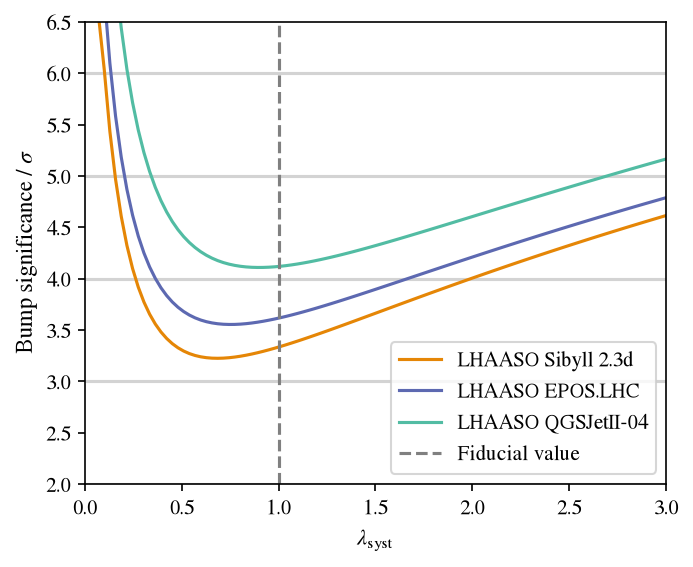

In [31]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))

for him, res in res_by_him.items():
    ax.plot(*res, label="LHAASO " + him_label[him], color=him_color[him])
ax.axvline(1.0, color="gray", ls="--", label="Fiducial value")
for sigmas in (2, 3, 4, 5, 6):
    ax.axhline(sigmas, color="lightgray", ls="-", zorder=-10)

ax.set_xlabel("$\\lambda_\\text{syst}$")
ax.set_xlim(0, 3)
ax.set_ylim(2, 6.5)
ax.legend()
ax.set_ylabel("Bump significance / $\\sigma$")

fig.savefig("../out/bump_significance.pdf")